# Mini2P FFT notch stripe removal

This notebook tries to remove the Mini2P vertical stripe artifact using **frequency-domain notch filtering**.

This is useful when stripes:

- are periodic,
- pulsate/change width over time,
- remain visible after column-profile/background subtraction,
- are detected by Suite2p as ROIs.

The workflow is:

1. Read a small preview from the GCaMP channel.
2. Compute the FFT power spectrum.
3. Automatically detect likely stripe-frequency peaks.
4. Preview correction on a small chunk.
5. Adjust notch parameters if needed.
6. Apply the correction to the full interleaved signal channel.
7. Save a new Suite2p-friendly TIFF.

Assumed raw TIFF shape: `frames x height x width`.

For your file this looked like `(21820, 512, 512)`.

In [1]:
import os
import gc
import numpy as np
import tifffile
import matplotlib.pyplot as plt

# ----------------------------
# User settings
# ----------------------------
path = "/Users/megyoung/Desktop/mini2p Images/72Lgoodtask"  # CHANGE THIS
selected_tiff = "72ltask_00001.tif"  # CHANGE THIS if needed

tiff_path = os.path.join(path, selected_tiff)

# Which interleaved channel is GCaMP / functional?
# 0 means raw frames 0, 2, 4, ...
# 1 means raw frames 1, 3, 5, ...
signal_channel = 1

# Optional red/structural channel for FFT peak finding only.
# Leave as None if you only want to use the signal channel.
reference_channel = 0

# Processing size. Lower if kernel crashes.
chunk_size = 10

base = os.path.splitext(selected_tiff)[0]

In [2]:
# ----------------------------
# Inspect TIFF without loading whole thing
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Raw frames:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

signal_frames = np.arange(signal_channel, n_pages, 2)
print("Signal frames:", len(signal_frames))

if reference_channel is not None:
    reference_frames = np.arange(reference_channel, n_pages, 2)
    print("Reference frames:", len(reference_frames))

Raw frames: 21820
Height: 512
Width: 512
dtype: int16
Signal frames: 10910
Reference frames: 10910


In [3]:
def read_pages_from_open_tif(tif, frame_indices):
    return np.stack([tif.pages[int(i)].asarray() for i in frame_indices], axis=0)


def robust_rescale_for_display(img, low=1, high=99):
    img = img.astype(np.float32)
    vmin, vmax = np.nanpercentile(img, [low, high])
    return np.clip((img - vmin) / (vmax - vmin + 1e-8), 0, 1)


def preview_interleaved_channel(tiff_path, channel, n_frames=200, start=0):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        channel_frames = np.arange(channel, n_pages, 2)
        inds = channel_frames[start:start + n_frames]
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img


def convert_for_suite2p(chunk, output_dtype=np.uint16):
    if output_dtype == np.uint16:
        return np.clip(chunk, 0, 65535).astype(np.uint16)

    if output_dtype == np.int16:
        info = np.iinfo(np.int16)
        return np.clip(chunk, info.min, info.max).astype(np.int16)

    return chunk.astype(output_dtype)

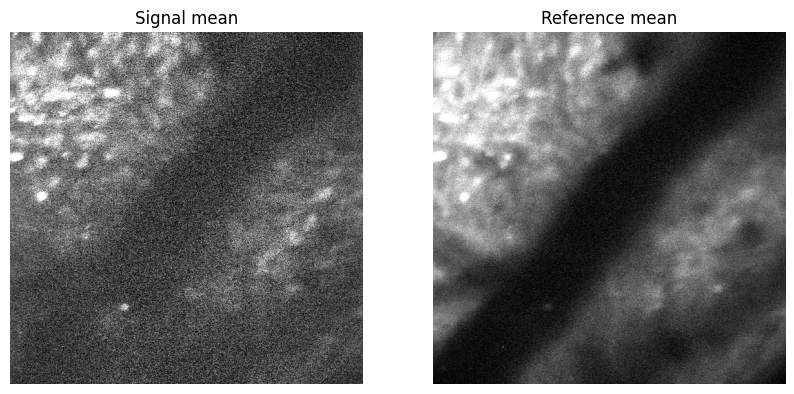

In [4]:
# ----------------------------
# Make preview mean image
# ----------------------------
preview_n_frames = 300
preview_start = 0

signal_mean = preview_interleaved_channel(
    tiff_path,
    channel=signal_channel,
    n_frames=preview_n_frames,
    start=preview_start
)

if reference_channel is not None:
    reference_mean = preview_interleaved_channel(
        tiff_path,
        channel=reference_channel,
        n_frames=preview_n_frames,
        start=preview_start
    )
else:
    reference_mean = None

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(robust_rescale_for_display(signal_mean), cmap="gray")
plt.title("Signal mean")
plt.axis("off")

if reference_mean is not None:
    plt.subplot(1, 2, 2)
    plt.imshow(robust_rescale_for_display(reference_mean), cmap="gray")
    plt.title("Reference mean")
    plt.axis("off")

plt.show()

## Inspect FFT spectrum

For vertical stripes, look for bright peaks away from the center along the **horizontal frequency axis**.

The central bright spot is normal image structure. The stripe artifact usually appears as symmetric peaks to the left/right of the center.

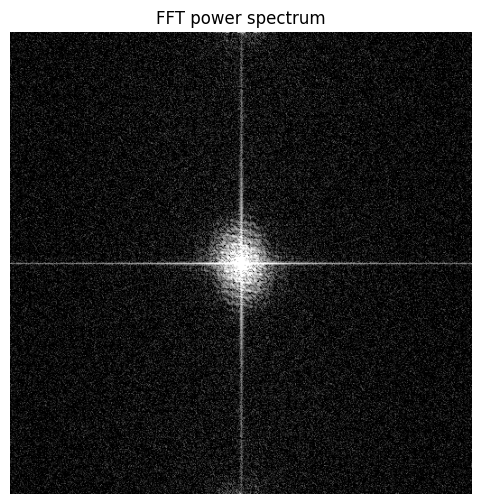

In [5]:
def fft_power_spectrum(img):
    img = img.astype(np.float32)

    # subtract smooth-ish baseline using median only
    img0 = img - np.median(img)

    F = np.fft.fftshift(np.fft.fft2(img0))
    power = np.log1p(np.abs(F))

    return power


# Use reference mean for finding artifact if available, otherwise signal mean
fft_source = reference_mean if reference_mean is not None else signal_mean
power = fft_power_spectrum(fft_source)

plt.figure(figsize=(6, 6))
plt.imshow(robust_rescale_for_display(power, low=50, high=99.8), cmap="gray")
plt.title("FFT power spectrum")
plt.axis("off")
plt.show()

Candidate notch x-offsets from FFT center:
[np.int64(21), np.int64(24), np.int64(27), np.int64(-31), np.int64(34), np.int64(-37), np.int64(-41), np.int64(-47), np.int64(44), np.int64(53)]


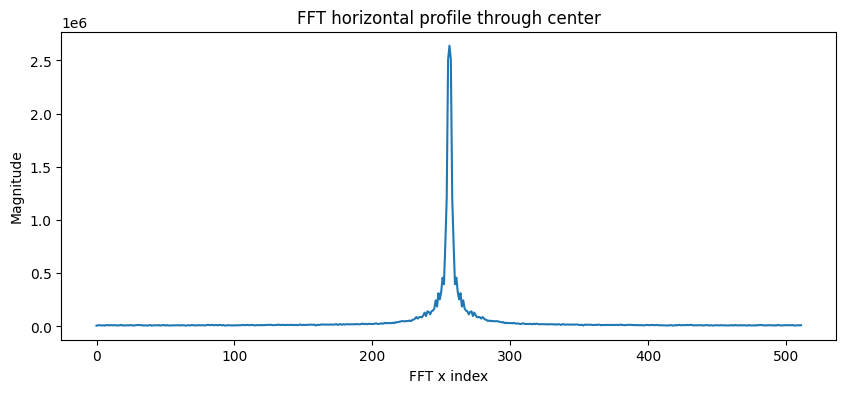

In [6]:
def find_candidate_notches_for_vertical_stripes(img, min_radius=5, exclude_center=20, n_peaks=8):
    """
    Detect likely vertical-stripe peaks in FFT.

    Vertical stripes vary across x, so peaks appear along horizontal frequency axis
    around the center row.

    Returns candidate x-offsets from FFT center.
    """
    img = img.astype(np.float32)
    h, w = img.shape

    F = np.fft.fftshift(np.fft.fft2(img - np.median(img)))
    mag = np.abs(F)

    cy, cx = h // 2, w // 2

    # Average a few rows around center frequency-y
    band_half_width = 3
    horizontal_profile = np.mean(
        mag[cy - band_half_width:cy + band_half_width + 1, :],
        axis=0
    )

    # remove center region
    profile = horizontal_profile.copy()
    profile[cx - exclude_center:cx + exclude_center + 1] = 0

    # only consider both sides away from center
    candidate_indices = np.argsort(profile)[::-1]

    offsets = []
    for idx in candidate_indices:
        offset = idx - cx
        if abs(offset) < min_radius:
            continue

        # keep unique absolute frequencies
        if all(abs(abs(offset) - abs(o)) > 2 for o in offsets):
            offsets.append(offset)

        if len(offsets) >= n_peaks:
            break

    return offsets, horizontal_profile


candidate_offsets, horizontal_profile = find_candidate_notches_for_vertical_stripes(
    fft_source,
    min_radius=5,
    exclude_center=20,
    n_peaks=10
)

print("Candidate notch x-offsets from FFT center:")
print(candidate_offsets)

plt.figure(figsize=(10, 4))
plt.plot(horizontal_profile)
plt.title("FFT horizontal profile through center")
plt.xlabel("FFT x index")
plt.ylabel("Magnitude")
plt.show()

## Choose notch settings

Start by using the automatically detected offsets.

If correction does nothing, choose stronger/wider notches.

If correction blurs or damages cells, reduce `notch_radius`, reduce `notch_depth`, or remove some offsets.

- `notch_offsets_x`: x-frequency offsets from FFT center. Use positive values; the code removes both `+offset` and `-offset`.
- `notch_radius`: width of each notch in Fourier pixels.
- `notch_depth`: 1.0 fully removes the frequency; 0.5 only partly suppresses it.
- `center_band_y`: how many FFT pixels above/below center row to notch. For vertical stripes, usually small: 1–5.

In [17]:
# ----------------------------
# Notch parameters
# ----------------------------

# Convert candidates to positive unique offsets.
auto_offsets = sorted(set([abs(int(o)) for o in candidate_offsets]))

print("Auto positive offsets:", auto_offsets)

# Start with the strongest first few offsets.
# You can manually override this, e.g. notch_offsets_x = [8, 16, 24]
notch_offsets_x = auto_offsets[:16]

# Width of each notch
notch_radius = 3

# How much to suppress selected frequencies: 1.0 = full removal
notch_depth = 1.0

# For vertical stripes, notch around center y-frequency
center_band_y = 5

print("Using notch_offsets_x:", notch_offsets_x)

Auto positive offsets: [21, 24, 27, 31, 34, 37, 41, 44, 47, 53]
Using notch_offsets_x: [21, 24, 27, 31, 34, 37, 41, 44, 47, 53]


In [18]:
def make_vertical_stripe_notch_mask(shape, offsets_x, notch_radius=2, notch_depth=1.0, center_band_y=3):
    """
    Make FFT mask for vertical stripes.

    shape: image shape, height x width
    offsets_x: positive x-frequency offsets from FFT center.
    notch_radius: radius around each peak.
    notch_depth: 1.0 = zero out; 0.5 = suppress by 50%.
    center_band_y: apply near center y-frequency.
    """
    h, w = shape
    cy, cx = h // 2, w // 2

    mask = np.ones((h, w), dtype=np.float32)

    yy, xx = np.ogrid[:h, :w]

    for ox in offsets_x:
        for sign in [-1, 1]:
            px = cx + sign * int(ox)
            py = cy

            dist2 = (xx - px) ** 2 + ((yy - py) / max(center_band_y, 1)) ** 2
            notch = dist2 <= notch_radius ** 2

            mask[notch] *= (1.0 - notch_depth)

    return mask


def apply_fft_notch_filter_frame(frame, mask, preserve_baseline=True):
    frame = frame.astype(np.float32)

    baseline = np.median(frame)

    F = np.fft.fftshift(np.fft.fft2(frame - baseline))
    Ff = F * mask
    corrected = np.real(np.fft.ifft2(np.fft.ifftshift(Ff))) + baseline

    if preserve_baseline:
        corrected = corrected - np.median(corrected) + np.median(frame)

    return corrected.astype(np.float32)


def apply_fft_notch_filter_chunk(chunk, mask, preserve_baseline=True):
    chunk = chunk.astype(np.float32)
    corrected = np.empty_like(chunk, dtype=np.float32)

    for i in range(chunk.shape[0]):
        corrected[i] = apply_fft_notch_filter_frame(
            chunk[i],
            mask=mask,
            preserve_baseline=preserve_baseline
        )

    return corrected

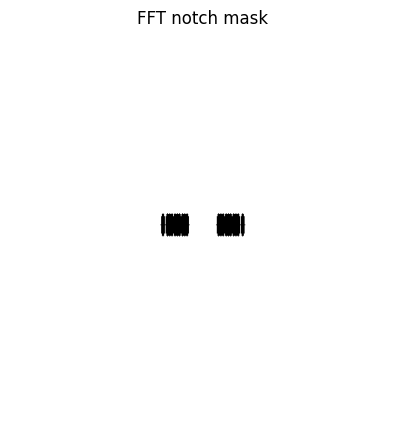

In [19]:
# ----------------------------
# Visualize notch mask
# ----------------------------
mask = make_vertical_stripe_notch_mask(
    shape=signal_mean.shape,
    offsets_x=notch_offsets_x,
    notch_radius=notch_radius,
    notch_depth=notch_depth,
    center_band_y=center_band_y
)

plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap="gray")
plt.title("FFT notch mask")
plt.axis("off")
plt.show()

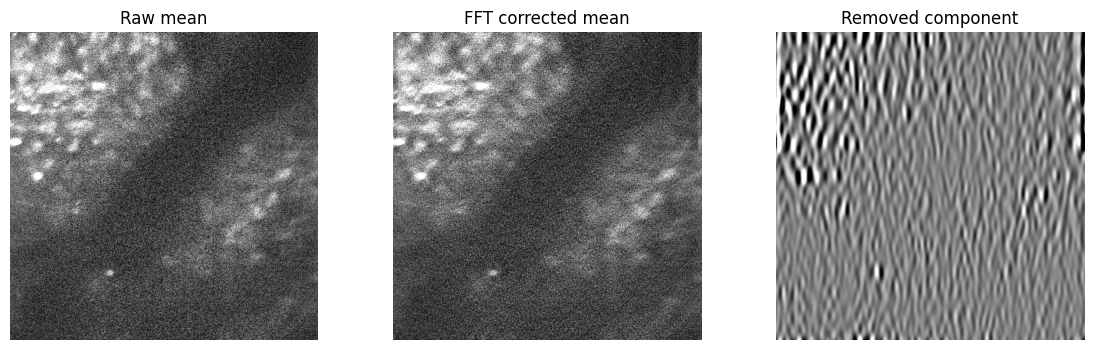

Raw mean range: [ 84.32666779 106.30999756 151.71000671]
Corrected mean range: [ 84.28411346 106.31000137 151.09612228]
Removed range: [-4.46901573  0.03261566  4.51999252]


In [20]:
# ----------------------------
# Preview correction on mean image
# ----------------------------
corrected_mean_fft = apply_fft_notch_filter_frame(signal_mean, mask)
removed_mean_fft = signal_mean - corrected_mean_fft

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(signal_mean), cmap="gray")
plt.title("Raw mean")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(corrected_mean_fft), cmap="gray")
plt.title("FFT corrected mean")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(removed_mean_fft), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

print("Raw mean range:", np.percentile(signal_mean, [1, 50, 99]))
print("Corrected mean range:", np.percentile(corrected_mean_fft, [1, 50, 99]))
print("Removed range:", np.percentile(removed_mean_fft, [1, 50, 99]))

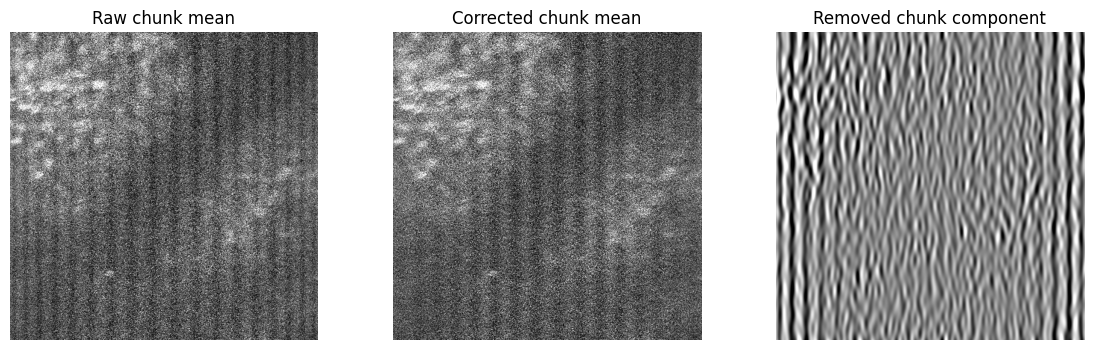

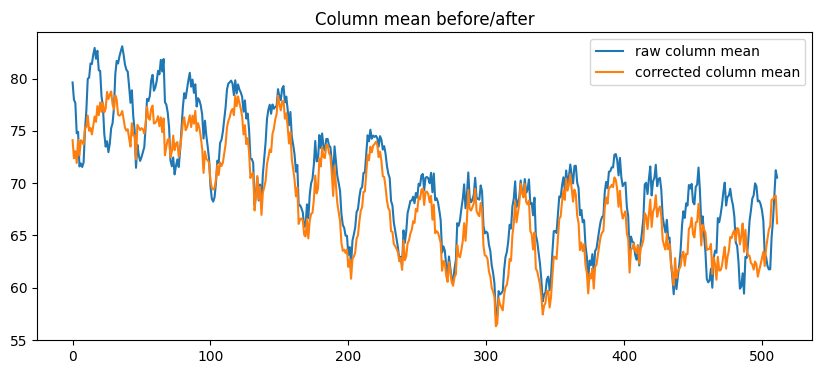

3401

In [21]:
# ----------------------------
# Preview correction on an actual chunk of frames
# ----------------------------
preview_chunk_n = 50
preview_chunk_start = 0

with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    signal_frames = np.arange(signal_channel, n_pages, 2)
    inds = signal_frames[preview_chunk_start:preview_chunk_start + preview_chunk_n]
    raw_chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

corrected_chunk = apply_fft_notch_filter_chunk(raw_chunk, mask)

raw_chunk_mean = np.mean(raw_chunk, axis=0)
corrected_chunk_mean = np.mean(corrected_chunk, axis=0)
removed_chunk_mean = raw_chunk_mean - corrected_chunk_mean

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(raw_chunk_mean), cmap="gray")
plt.title("Raw chunk mean")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(corrected_chunk_mean), cmap="gray")
plt.title("Corrected chunk mean")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(removed_chunk_mean), cmap="gray")
plt.title("Removed chunk component")
plt.axis("off")

plt.show()

plt.figure(figsize=(10, 4))
plt.plot(np.mean(raw_chunk_mean, axis=0), label="raw column mean")
plt.plot(np.mean(corrected_chunk_mean, axis=0), label="corrected column mean")
plt.legend()
plt.title("Column mean before/after")
plt.show()

del raw_chunk, corrected_chunk
gc.collect()

## If the preview still has stripes

Try these changes and rerun the mask + preview cells:

```python
notch_offsets_x = auto_offsets[:8]
notch_radius = 3
notch_depth = 1.0
center_band_y = 5
```

If it removes too much structure:

```python
notch_offsets_x = auto_offsets[:2]
notch_radius = 1
notch_depth = 0.5
center_band_y = 2
```

If the automatic offsets are wrong, inspect the FFT image and manually set:

```python
notch_offsets_x = [8, 16, 24]
```

using the peak distances from the center.

In [ ]:
def run_fft_notch_correction(
    tiff_path,
    signal_channel,
    output_file,
    mask,
    chunk_size=10,
    output_dtype=np.uint16,
    preserve_baseline=True,
):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        signal_frames = np.arange(signal_channel, n_pages, 2)
        n = len(signal_frames)

        print("Saving to:", output_file)
        print("Frames to save:", n)

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, n, chunk_size):
                end = min(start + chunk_size, n)
                inds = signal_frames[start:end]

                chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

                corrected = apply_fft_notch_filter_chunk(
                    chunk,
                    mask=mask,
                    preserve_baseline=preserve_baseline,
                )

                corrected_to_save = convert_for_suite2p(corrected, output_dtype=output_dtype)
                writer.write(corrected_to_save, photometric="minisblack")

                print(f"Saved frames {start} to {end} / {n}")

                del chunk, corrected, corrected_to_save
                gc.collect()

    print("Done:", output_file)

In [ ]:
# ----------------------------
# Run full correction and save new TIFF
# ----------------------------
offset_string = "-".join([str(x) for x in notch_offsets_x])

output_file = os.path.join(
    path,
    f"{base}_unstriped_fft_ch{signal_channel}_offsets{offset_string}_r{notch_radius}.tiff"
)

run_fft_notch_correction(
    tiff_path=tiff_path,
    signal_channel=signal_channel,
    output_file=output_file,
    mask=mask,
    chunk_size=chunk_size,
    output_dtype=np.uint16,
    preserve_baseline=True,
)

In [ ]:
# ----------------------------
# Preview saved output
# ----------------------------
def preview_saved_tiff(tiff_path, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(0, min(n_pages, n_frames))
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img


saved_preview = preview_saved_tiff(output_file, n_frames=200)
raw_preview = preview_interleaved_channel(tiff_path, signal_channel, n_frames=200)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(raw_preview), cmap="gray")
plt.title("Raw signal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(saved_preview), cmap="gray")
plt.title("Saved FFT corrected")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(raw_preview - saved_preview), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

print("Saved corrected TIFF:")
print(output_file)